# HIỆU CHỈNH & CHUYỂN ĐỔI THANG ĐIỂM (SCORECARD)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("/home/kieu/Documents/scorecard/DATA")
OUTPUT_DIR = Path("/home/kieu/Documents/scorecard/output")
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET = "TARGET" 

## Phần A — Tham số định hình thang điểm

Thang điểm dịch tỷ lệ cược sang ngôn ngữ kinh doanh

| Tham số | Giá trị | Ý nghĩa |
|---|---|---|
| `TARGET_SCORE` | 600 | Điểm neo (base score) — mốc quy chiếu của cả thang |
| `TARGET_ODDS` | 50 | Tại 600 điểm: 50 khách trả tốt / 1 khách xấu |
| `PDO` | 20 | Points to Double the Odds — cộng 20 điểm, odds tốt **gấp đôi** |

Từ định nghĩa PDO suy ra hai hằng số dịch thuật:

$$Factor = \frac{PDO}{\ln 2} \qquad\qquad Offset = TARGET\_SCORE - Factor \times \ln(TARGET\_ODDS)$$

và điểm của một khách hàng: $Score = Offset - Factor \times \ln(odds_{bad})$.

**Lưu ý quan trọng:** đổi 3 tham số này **không đổi Gini** — chỉ đổi "đơn vị tiền tệ" của điểm.

In [2]:
# ===== 3 THAM SỐ THANG ĐIỂM (Đề C bài tập lớn: sửa ngay tại đây) =====
TARGET_SCORE = 600   # điểm neo (base score)
TARGET_ODDS = 50     # tại 600 điểm: 50 khách tốt / 1 khách xấu
PDO = 20             # cộng 20 điểm -> odds tốt gấp đôi

# Hai hằng số "dịch thuật" suy ra từ định nghĩa PDO
FACTOR = PDO / np.log(2)
OFFSET = TARGET_SCORE - FACTOR * np.log(TARGET_ODDS)

print(f"FACTOR = PDO / ln(2)           = {FACTOR:.4f}")
print(f"OFFSET = 600 - FACTOR x ln(50) = {OFFSET:.4f}\n")

# Kiểm chứng bài tập miệng: điểm ứng với các mức odds
for odds in [50, 100, 200]:
    score = OFFSET + FACTOR * np.log(odds)   # odds ở đây là good:bad
    print(f"Odds {odds:>3}:1  ->  {score:.1f} điểm")

FACTOR = PDO / ln(2)           = 28.8539
OFFSET = 600 - FACTOR x ln(50) = 487.1229

Odds  50:1  ->  600.0 điểm
Odds 100:1  ->  620.0 điểm
Odds 200:1  ->  640.0 điểm


### Đường cong Score ↔ Odds

Công thức $Score = Offset + Factor \times \ln(odds_{good})$ là một **hàm mũ ngược log** — nghĩa là trục điểm số *tuyến tính* (cộng trừ đều đặn) nhưng trục odds bên dưới nó *nhân theo cấp số nhân*. Đây là lý do khách hàng gọi thang điểm là "dễ hiểu": người dùng cuối chỉ thấy con số cộng trừ, còn phần rủi ro thực (odds, xác suất) luôn nhân/chia phía sau hậu trường.

Nhìn hình dưới: mỗi khi trục hoành (điểm) nhích thêm đúng **1 PDO**, điểm trên trục tung (odds, đang vẽ ở thang log) nhảy **gấp đôi**. Khoảng cách trên hình đều nhau — nhưng ý nghĩa rủi ro của mỗi bước nhảy đó lớn dần nếu nhìn bằng xác suất tuyệt đối ($p = \frac{1}{1+odds^{-1}}$), vì xác suất bị "nén" ở hai đầu (gần 0% và gần 100%) trong khi log-odds thì tuyến tính.

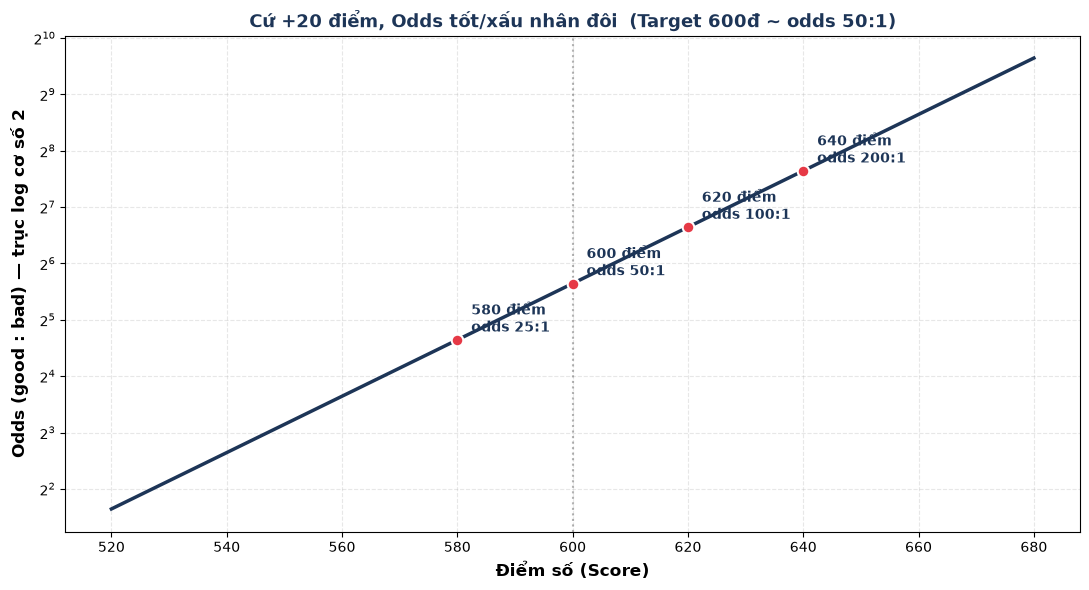

Đọc hình: mỗi bước nhảy ngang đều nhau (PDO điểm) luôn ứng với odds nhân đôi trên trục dọc.
không đổi thứ tự xếp hạng khách hàng (Gini không đổi).


In [3]:
# ===== MINH HOẠ: đường cong Score <-> Odds (trực quan hoá PDO) =====
fig, ax = plt.subplots(figsize=(11, 6))

s_grid = np.linspace(TARGET_SCORE - 4 * PDO, TARGET_SCORE + 4 * PDO, 300)
o_grid = TARGET_ODDS * (2 ** ((s_grid - TARGET_SCORE) / PDO))   # định nghĩa PDO: +PDO -> odds x2

ax.plot(s_grid, o_grid, color='#1D3557', linewidth=2.5, zorder=3)
ax.set_yscale('log', base=2)   # trục log cơ số 2: mỗi PDO là MỘT bước nhảy đều trên hình

# Đánh dấu 4 mốc: -1 PDO, điểm neo, +1 PDO, +2 PDO
for k in [-1, 0, 1, 2]:
    sx = TARGET_SCORE + k * PDO
    ox = TARGET_ODDS * (2 ** k)
    ax.scatter([sx], [ox], color='#E63946', s=70, zorder=5, edgecolor='white', linewidth=1.5)
    ax.annotate(f"{sx:.0f} điểm\nodds {ox:.0f}:1", (sx, ox), textcoords="offset points",
                xytext=(10, 6), fontsize=10, fontweight='bold', color='#1D3557')

ax.axvline(TARGET_SCORE, color='gray', linestyle=':', alpha=0.6)
ax.set_xlabel('Điểm số (Score)', fontsize=12, fontweight='bold')
ax.set_ylabel('Odds (good : bad) — trục log cơ số 2', fontsize=12, fontweight='bold')
ax.set_title(f'Cứ +{PDO} điểm, Odds tốt/xấu nhân đôi  (Target {TARGET_SCORE}đ ~ odds {TARGET_ODDS}:1)',
             fontsize=13, fontweight='bold', color='#1D3557')
ax.grid(True, which='both', linestyle='--', alpha=0.3)
fig.tight_layout()
plt.savefig(OUTPUT_DIR / "4b.Score_Odds_Curve.png", dpi=200, bbox_inches='tight')
plt.show()

print("Đọc hình: mỗi bước nhảy ngang đều nhau (PDO điểm) luôn ứng với odds nhân đôi trên trục dọc.")
print("không đổi thứ tự xếp hạng khách hàng (Gini không đổi).")

## Phần B — Phân bổ điểm về từng bin

Hồi quy cho ta $\ln(odds_{bad}) = \alpha + \sum_i \beta_i \cdot WoE_i$. Chia đều $\alpha$ và $Offset$ cho $n$ biến, điểm của **một bin** thuộc biến $i$:

$$Score(bin) = \frac{Offset}{n} - Factor \times \left(\frac{\alpha}{n} + \beta_i \times WoE_{bin}\right)$$

Dấu trừ trước $\beta \cdot WoE$: WoE càng "good" → điểm càng cao. **Tổng điểm khách = cộng điểm các bin họ rơi vào** — tính điểm cộng bằng máy tính tay được.



In [4]:
# 1. Nạp dữ liệu bước 3 + bảng luật binning
df_model = pd.read_csv(OUTPUT_DIR / "3.data_final_model.csv")
df_rules = pd.read_excel(OUTPUT_DIR / "1.binning_survey_report.xlsx")

y = df_model[TARGET]
X = df_model.drop(columns=[TARGET, 'SK_ID_CURR'], errors='ignore')
final_features = list(X.columns)
n_features = len(final_features)

# 2. Huấn luyện Logistic Regression — penalty=None BẮT BUỘC (xem lý do ở trên)
lr_model = LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000)
lr_model.fit(X, y)

y_pred_prob = lr_model.predict_proba(X)[:, 1]
auc = roc_auc_score(y, y_pred_prob)
gini = (2 * auc - 1) * 100
print(f"AUC = {auc:.4f} | GINI = {gini:.2f}% \n")

# 3. Lấy hệ số chặn (alpha) và hệ số góc (beta) của từng biến
intercept = lr_model.intercept_[0]
coefs = dict(zip(final_features, lr_model.coef_[0]))

# 4. Áp công thức phân bổ điểm cho TỪNG DÒNG BIN trong bảng luật
df_scorecard = df_rules[df_rules['variable'].isin(final_features)].copy()

def calculate_score(row):
    """Score(bin) = Offset/n - Factor x (alpha/n + beta x WoE)"""
    beta = coefs[row['variable']]
    point = (OFFSET / n_features) - FACTOR * ((intercept / n_features) + (beta * row['woe']))
    return round(point, 0)   # làm tròn số nguyên cho bảng điểm gọn đẹp

df_scorecard['Score_Points'] = df_scorecard.apply(calculate_score, axis=1)
df_scorecard = df_scorecard[['variable', 'bin_no', 'cut_point', 'min', 'max',
                             'badrate', 'total', 'woe', 'Score_Points']]

SCORECARD_PATH = OUTPUT_DIR / "4.FINAL_SCORECARD_REPORT.xlsx"
df_scorecard.to_excel(SCORECARD_PATH, index=False)
print(f"✅ Đã lưu bảng thẻ điểm: {SCORECARD_PATH}")
df_scorecard.head(12)

AUC = 0.7391 | GINI = 47.82% 

✅ Đã lưu bảng thẻ điểm: /home/kieu/Documents/scorecard/output/4.FINAL_SCORECARD_REPORT.xlsx


,variable,bin_no,cut_point,min,max,badrate,total,woe,Score_Points
85,EXT_SOURCE_AVG,1,"[-inf, 0.272)",-inf,0.272000,0.251550,15643,-1.305861,37.0
86,EXT_SOURCE_AVG,2,"[0.272, 0.367)",0.272000,0.367000,0.163598,20856,-0.764531,51.0
87,EXT_SOURCE_AVG,3,"[0.367, 0.426)",0.367000,0.426000,0.116417,20856,-0.369427,60.0
88,EXT_SOURCE_AVG,4,"[0.426, 0.554)",0.426000,0.554000,0.072945,62568,0.146078,73.0
89,EXT_SOURCE_AVG,5,"[0.554, inf)",0.554000,inf,0.034568,88638,0.933423,93.0
90,EXT_SOURCE_AVG,6,Missing,NaN,NaN,0.115044,113,-0.355441,61.0
114,LTV_RATIO,1,"[-inf, 0.759419)",-inf,0.759419,0.129279,20885,-0.488885,60.0
115,LTV_RATIO,2,"[0.759419, 0.86326)",0.759419,0.863260,0.099454,61576,-0.192931,66.0
116,LTV_RATIO,3,"[0.86326, 0.909918)",0.863260,0.909918,0.070323,48263,0.185503,73.0
117,LTV_RATIO,4,"[0.909918, 0.94511)",0.909918,0.945110,0.049293,15357,0.563170,80.0


## Phần C — Master Scale 10 hạng: "đầu phình – đuôi nhọn"

**Tham số của phần này** là bảng phân bổ dân số mục tiêu — một quyết định *kinh doanh* chứ không phải toán học:
- **G1–G7 = 90% dân số** — nới rộng để lấy volume, bad rate thấp và mượt (vùng phê duyệt);
- **G8–G10 = 10% rủi ro nhất** — bóp chặt (5%/3%/2%) để bad rate ở đuôi *bật* lên rõ, phục vụ đặt cut-off từ chối / review tay.

Trong thực tế ngân hàng, hạng dùng để: định giá lãi suất theo rủi ro, phê duyệt tự động, và cấp hạn mức.

In [5]:
# ===== PHÂN BỔ DÂN SỐ MỤC TIÊU — từ XẤU NHẤT (G10) đến TỐT NHẤT (G1) =====
# (Đề B bài tập lớn: thiết kế lại bảng này ngay tại đây)
target_dist = [
    0.02,  # Grade 10: 2%  (vũng lõm rủi ro cao nhất)
    0.03,  # Grade 09: 3%
    0.05,  # Grade 08: 5%  (tổng G8-G10 = 10% -> bóp chặt cho bad rate bật lên)
    0.10,  # Grade 07: 10%
    0.15,  # Grade 06: 15%
    0.20,  # Grade 05: 20% (đông dân nhất)
    0.15,  # Grade 04: 15%
    0.15,  # Grade 03: 15%
    0.10,  # Grade 02: 10%
    0.05,  # Grade 01: 5%  (tổng G1-G7 = 90% -> vùng lấy volume)
]
grade_labels = [10, 9, 8, 7, 6, 5, 4, 3, 2, 1]   # gán theo thứ tự điểm TĂNG dần

# Kiểm tra an toàn: tổng tỷ trọng phải bằng 100%
assert round(sum(target_dist), 5) == 1.0, "Tổng tỷ trọng không bằng 100%!"

# --- 1. Tính tổng điểm cho từng khách hàng Train ---
log_odds = lr_model.decision_function(X)
df_model['TOTAL_SCORE'] = (OFFSET - FACTOR * log_odds).round(0).astype(int)

# --- 2. Tìm mốc điểm cắt (cut-offs) theo phân vị của phân bổ mục tiêu ---
cum_dist = [0] + list(np.cumsum(target_dist))
cum_dist[-1] = 1.0
cut_offs = df_model['TOTAL_SCORE'].quantile(cum_dist).values.copy()   # .copy(): pandas mới trả mảng read-only
cut_offs[0], cut_offs[-1] = -np.inf, np.inf   # mở 2 đầu mút đón khách ngoài vùng

df_model['RISK_GRADE'] = pd.cut(df_model['TOTAL_SCORE'], bins=cut_offs,
                                labels=grade_labels, include_lowest=True).astype(int)

# --- 3. Báo cáo Master Scale ---
summary = df_model.groupby('RISK_GRADE').agg(
    Min_Score=('TOTAL_SCORE', 'min'),
    Max_Score=('TOTAL_SCORE', 'max'),
    Total_Customers=('TOTAL_SCORE', 'count'),
    Bad_Customers=(TARGET, 'sum'),
).reset_index()

summary['Good_Customers'] = summary['Total_Customers'] - summary['Bad_Customers']
summary['Bad_Rate (%)'] = round(summary['Bad_Customers'] / summary['Total_Customers'] * 100, 2)
summary['%_Population'] = round(summary['Total_Customers'] / len(df_model) * 100, 2)
summary['Cum_Total_Customers'] = summary['Total_Customers'].cumsum()
summary['Cum_Bad_Customers'] = summary['Bad_Customers'].cumsum()
summary['Cum_Bad_Rate (%)'] = round(summary['Cum_Bad_Customers'] / summary['Cum_Total_Customers'] * 100, 2)

summary = summary.sort_values('RISK_GRADE').reset_index(drop=True)
summary = summary[['RISK_GRADE', 'Min_Score', 'Max_Score', 'Total_Customers',
                   '%_Population', 'Good_Customers', 'Bad_Customers',
                   'Bad_Rate (%)', 'Cum_Bad_Rate (%)']]

MASTER_SCALE_PATH = OUTPUT_DIR / "5.MASTER_SCALE_HIGH_VOLUME.xlsx"
summary.to_excel(MASTER_SCALE_PATH, index=False)
df_model.to_csv(OUTPUT_DIR / "5.Customers_Scored_HighVolume.csv", index=False)
print(f"✅ Đã lưu: {MASTER_SCALE_PATH.name}\n")
summary

✅ Đã lưu: 5.MASTER_SCALE_HIGH_VOLUME.xlsx



,RISK_GRADE,Min_Score,Max_Score,Total_Customers,%_Population,Good_Customers,Bad_Customers,Bad_Rate (%),Cum_Bad_Rate (%)
0,1,600,611,9571,4.59,9393,178,1.86,1.86
1,2,592,599,20228,9.69,19805,423,2.09,2.02
2,3,582,591,32780,15.71,31794,986,3.01,2.54
3,4,573,581,29700,14.23,28468,1232,4.15,3.05
4,5,559,572,40901,19.60,38363,2538,6.21,4.02
5,6,544,558,33720,16.16,30219,3501,10.38,5.31
6,7,531,543,20227,9.69,17183,3044,15.05,6.36
7,8,521,530,10676,5.12,8534,2142,20.06,7.10
8,9,511,520,6290,3.01,4625,1665,26.47,7.70
9,10,463,510,4581,2.20,2874,1707,37.26,8.35


## Phần C2 — Áp Master Scale sang Validation: kiểm tra ngoài mẫu?

In [6]:
# 1. Áp luật WoE của Train (df_rules) lên Validation — chưa từng thấy khi fit model/cut_offs
df_valid_raw = pd.read_csv(OUTPUT_DIR / "0.data_valid_split.csv")

def apply_woe_rules(df_raw, df_rules, features):
    """Áp bảng luật WoE (Train) lên một tập dữ liệu bất kỳ. Giá trị không khớp luật -> WoE = 0.
       (Đây là logic sẽ được giải thích đầy đủ ở Phần E — dùng trước cho Validation.)"""
    df_woe = pd.DataFrame(index=df_raw.index)   # giữ đúng số dòng của df_raw ngay từ đầu
    for col in features:
        var_rules = df_rules[df_rules['variable'] == col]
        df_woe[col] = np.nan
        m_rule = var_rules[var_rules['cut_point'] == 'Missing']
        if not m_rule.empty:
            df_woe.loc[df_raw[col].isna(), col] = m_rule['woe'].values[0]
        normal_rules = var_rules[~var_rules['cut_point'].isin(['Missing'])
                                 & ~var_rules['cut_point'].astype(str).str.contains('Outlier')]
        is_categorical = df_raw[col].dtype == 'object'
        if is_categorical:
            for _, r in normal_rules.iterrows():
                if r['cut_point'] == 'OTHERS':
                    known_cats = normal_rules['cut_point'].tolist()
                    df_woe.loc[~df_raw[col].isna() & ~df_raw[col].isin(known_cats), col] = r['woe']
                else:
                    df_woe.loc[df_raw[col] == r['cut_point'], col] = r['woe']
        else:
            for _, r in normal_rules.iterrows():
                cond = (df_raw[col] >= float(r['min'])) & (df_raw[col] < float(r['max']))
                df_woe.loc[cond, col] = r['woe']
    return df_woe.fillna(0)

X_valid = apply_woe_rules(df_valid_raw, df_rules, final_features)

# 2. Chấm điểm bằng ĐÚNG mô hình + ĐÚNG Factor/Offset của Phần A — không fit lại gì
log_odds_valid = lr_model.decision_function(X_valid)
df_valid_scored = df_valid_raw[[TARGET]].copy()
df_valid_scored['TOTAL_SCORE'] = (OFFSET - FACTOR * log_odds_valid).round(0).astype(int)

# 3. Bỏ vào ĐÚNG cut_offs đã cắt từ Train ở Phần C — không cắt lại
df_valid_scored['RISK_GRADE'] = pd.cut(df_valid_scored['TOTAL_SCORE'], bins=cut_offs,
                                       labels=grade_labels, include_lowest=True).astype(int)

# 4. Master Scale trên Validation, đối chiếu song song với Train
summary_valid = df_valid_scored.groupby('RISK_GRADE').agg(
    Total_Customers=('TOTAL_SCORE', 'count'),
    Bad_Customers=(TARGET, 'sum'),
).reset_index()
summary_valid['Bad_Rate (%)'] = round(summary_valid['Bad_Customers'] / summary_valid['Total_Customers'] * 100, 2)
summary_valid['%_Population'] = round(summary_valid['Total_Customers'] / len(df_valid_scored) * 100, 2)
summary_valid = summary_valid.sort_values('RISK_GRADE').reset_index(drop=True)

compare = summary[['RISK_GRADE', 'Bad_Rate (%)', '%_Population']].rename(
    columns={'Bad_Rate (%)': 'Bad_Rate_Train (%)', '%_Population': 'Pop_Train (%)'}).merge(
    summary_valid[['RISK_GRADE', 'Bad_Rate (%)', '%_Population']].rename(
        columns={'Bad_Rate (%)': 'Bad_Rate_Valid (%)', '%_Population': 'Pop_Valid (%)'}),
    on='RISK_GRADE')

VALID_MASTER_SCALE_PATH = OUTPUT_DIR / "6b.MasterScale_Validation_Check.xlsx"
compare.to_excel(VALID_MASTER_SCALE_PATH, index=False)

# 5. Rank ordering trên Validation có đơn điệu không? (đi từ G1 -> G10, bad rate phải tăng)
rates_valid_sorted = summary_valid.sort_values('RISK_GRADE')['Bad_Rate (%)'].values
is_monotonic = np.all(np.diff(rates_valid_sorted) >= -1e-9)
print(f"Rank ordering trên Validation {'✅ đơn điệu' if is_monotonic else '❌ GÃY — có hạng bad rate đi ngược'}")
print(f"\n💾 Đã lưu: {VALID_MASTER_SCALE_PATH.name}")
compare

Rank ordering trên Validation ✅ đơn điệu

💾 Đã lưu: 6b.MasterScale_Validation_Check.xlsx


,RISK_GRADE,Bad_Rate_Train (%),Pop_Train (%),Bad_Rate_Valid (%),Pop_Valid (%)
0,1,1.86,4.59,1.62,5.25
1,2,2.09,9.69,1.88,9.10
2,3,3.01,15.71,2.94,15.46
3,4,4.15,14.23,4.24,14.39
4,5,6.21,19.60,6.26,19.78
5,6,10.38,16.16,9.98,16.21
6,7,15.05,9.69,15.88,9.59
7,8,20.06,5.12,20.96,5.08
8,9,26.47,3.01,27.13,3.01
9,10,37.26,2.20,36.05,2.12


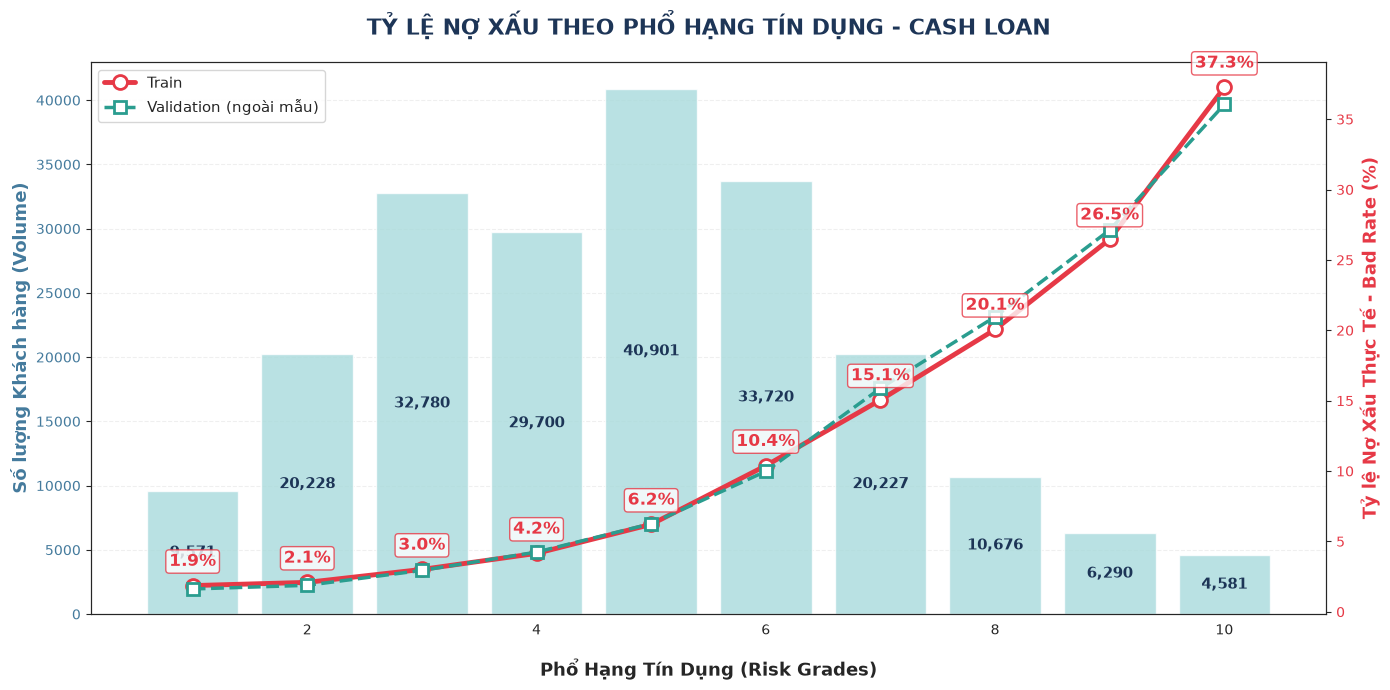

Rank ordering đơn điệu G1->G10: ✅ ĐẠT
Rank ordering đơn điệu trên Validation: ✅ ĐẠT


In [7]:
df_summary = pd.read_excel(MASTER_SCALE_PATH)

sns.set_style("white")
fig, ax1 = plt.subplots(figsize=(14, 7))

# --- Trục trái: cột số lượng khách hàng ---
color_bar = '#A8DADC'
ax1.bar(df_summary['RISK_GRADE'], df_summary['Total_Customers'], color=color_bar, edgecolor='white', alpha=0.8)
ax1.set_xlabel('Phổ Hạng Tín Dụng (Risk Grades)', fontsize=13, fontweight='bold', labelpad=15)
ax1.set_ylabel('Số lượng Khách hàng (Volume)', color='#457B9D', fontsize=13, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#457B9D')
ax1.grid(axis='y', linestyle='--', alpha=0.3)
for i, v in enumerate(df_summary['Total_Customers']):
    ax1.text(i + 1, v / 2, f"{v:,.0f}", color='#1D3557', fontweight='bold', ha='center', va='center', fontsize=11)

# --- Trục phải: đường bad rate ---
ax2 = ax1.twinx()
color_line = '#E63946'
ax2.plot(df_summary['RISK_GRADE'], df_summary['Bad_Rate (%)'], color=color_line,
         marker='o', linewidth=3.5, markersize=10, markerfacecolor='white', markeredgewidth=2,
         label='Train')
ax2.plot(summary_valid['RISK_GRADE'], summary_valid['Bad_Rate (%)'], color='#2A9D8F',
         marker='s', linewidth=2.5, linestyle='--', markersize=8, markerfacecolor='white',
         markeredgewidth=2, label='Validation (ngoài mẫu)')
ax2.legend(loc='upper left', fontsize=11, frameon=True)
ax2.set_ylabel('Tỷ lệ Nợ Xấu Thực Tế - Bad Rate (%)', color=color_line, fontsize=13, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_line)
for i, v in enumerate(df_summary['Bad_Rate (%)']):
    ax2.text(i + 1, v + df_summary['Bad_Rate (%)'].max() * 0.03, f"{v:.1f}%",
             color=color_line, fontweight='bold', ha='center', va='bottom', fontsize=12,
             bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=color_line, alpha=0.8))

plt.title('TỶ LỆ NỢ XẤU THEO PHỔ HẠNG TÍN DỤNG - CASH LOAN',
          fontsize=16, fontweight='bold', color='#1D3557', pad=20)
fig.tight_layout()
plt.savefig(OUTPUT_DIR / "6.Rank_Ordering_BadRate_Chart.png", dpi=300, bbox_inches='tight')
plt.show()

mono = np.all(np.diff(df_summary.sort_values('RISK_GRADE')['Bad_Rate (%)'].values) >= 0)
print(f"Rank ordering đơn điệu G1->G10: {'✅ ĐẠT' if mono else '❌ GÃY — truy ngược theo 3 câu hỏi ở trên!'}")

mono_valid = np.all(np.diff(summary_valid.sort_values('RISK_GRADE')['Bad_Rate (%)'].values) >= -1e-9)
print(f"Rank ordering đơn điệu trên Validation: {'✅ ĐẠT' if mono_valid else '❌ GÃY — xem lại Phần C2!'}")

## Phần D2 — Phổ điểm 

Biểu đồ Rank Ordering ở Phần D trả lời "bad rate có tăng đúng thứ tự không". **Phổ điểm** trả lời một câu khác, ở tầm nhìn danh mục: *"Nếu ngân hàng duyệt/từ chối tại một mốc hạng bất kỳ, hệ quả volume và rủi ro là gì?"*

Ba đại lượng cần đọc cùng lúc, theo đúng thứ tự **G1 (điểm cao nhất) → G10 (điểm thấp nhất)**:

| Đại lượng | Ý nghĩa | Đọc theo hướng nào |
|---|---|---|
| **% Population** (cột) | Bao nhiêu % khách rơi vào hạng này | Không có hướng bắt buộc — nhưng phải khớp `target_dist` đã thiết kế |
| **Bad Rate biên (%)** | Rủi ro *riêng* của hạng đó | Phải **tăng đơn điệu** G1→G10 (đây chính là Rank Ordering) |
| **Bad Rate luỹ kế (%)** | Nếu duyệt hết từ G1 đến hạng này, rủi ro bình quân cả nhóm đã duyệt là bao nhiêu | Cũng **tăng đơn điệu** G1→G10, và **hội tụ về bad rate chung của toàn Train** tại G10 (vì lúc đó luỹ kế = 100% dân số) |

**Cách một giám đốc rủi ro dùng biểu đồ này để đặt cut-off:** chọn một hạng làm ranh giới duyệt/từ chối; *Bad Rate luỹ kế* tại đúng hạng đó chính là bad rate bình quân của toàn bộ portfolio **nếu duyệt đến hạng đó và dừng**. Dời cut-off sang phải 1 hạng → nhận thêm % Population của hạng đó, nhưng kéo Bad Rate luỹ kế lên gần với Bad Rate biên của hạng vừa nhận thêm. Đây là đánh đổi volume-vs-risk kinh điển, và Phổ điểm là biểu đồ duy nhất cho thấy cả hai trục cùng lúc.

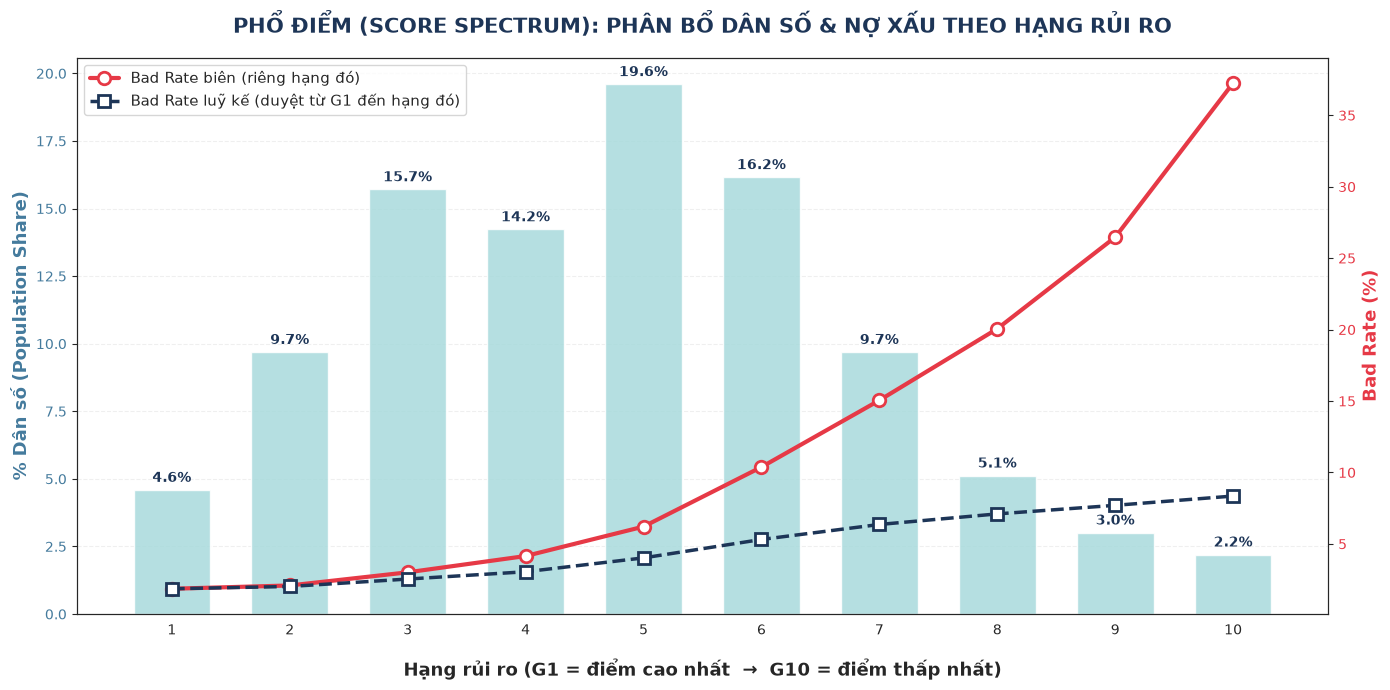


📊 Bảng Phổ điểm & Nợ xấu luỹ kế (G1=Tốt → G10=Xấu):
 HẠNG  Min_Score  Max_Score  %_Dân_số  Bad_Rate_biên (%)  %_Duyệt_nếu_cắt_từ_G1_đến_Gi  %_Từ_chối_nếu_cắt_từ_G1_đến_Gi
    1        600        611      4.59               1.86                          4.59                           95.41
    2        592        599      9.69               2.09                         14.28                           85.72
    3        582        591     15.71               3.01                         29.99                           70.01
    4        573        581     14.23               4.15                         44.22                           55.78
    5        559        572     19.60               6.21                         63.82                           36.18
    6        544        558     16.16              10.38                         79.98                           20.02
    7        531        543      9.69              15.05                         89.67                           1

In [8]:
# ===== PHẦN D2: Biểu đồ PHỔ ĐIỂM (Code cũ + Bảng FIXED) =====

fig, ax1 = plt.subplots(figsize=(14, 7))

# --- Cột: % dân số mỗi hạng ---
color_bar = '#A8DADC'
ax1.bar(summary['RISK_GRADE'], summary['%_Population'], color=color_bar,
        edgecolor='white', alpha=0.85, width=0.65, label='% Population')
ax1.set_xlabel('Hạng rủi ro (G1 = điểm cao nhất  →  G10 = điểm thấp nhất)',
               fontsize=13, fontweight='bold', labelpad=15)
ax1.set_ylabel('% Dân số (Population Share)', color='#457B9D', fontsize=13, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#457B9D')
ax1.set_xticks(summary['RISK_GRADE'])
ax1.grid(axis='y', linestyle='--', alpha=0.3)
for i, v in zip(summary['RISK_GRADE'], summary['%_Population']):
    ax1.text(i, v + 0.3, f"{v:.1f}%", color='#1D3557', fontweight='bold', ha='center', fontsize=10)

# --- Đường: Bad rate biên (từng hạng riêng) ---
ax2 = ax1.twinx()
ax2.plot(summary['RISK_GRADE'], summary['Bad_Rate (%)'], color='#E63946',
         marker='o', linewidth=3, markersize=9, markerfacecolor='white', markeredgewidth=2,
         label='Bad Rate biên (riêng hạng đó)')

# --- Đường: Bad rate luỹ kế (từ G1 dồn đến hạng đó) ---
ax2.plot(summary['RISK_GRADE'], summary['Cum_Bad_Rate (%)'], color='#1D3557',
         marker='s', linewidth=2.5, linestyle='--', markersize=8, markerfacecolor='white',
         markeredgewidth=2, label='Bad Rate luỹ kế (duyệt từ G1 đến hạng đó)')

ax2.set_ylabel('Bad Rate (%)', color='#E63946', fontsize=13, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#E63946')
ax2.legend(loc='upper left', fontsize=10.5, frameon=True)

plt.title('PHỔ ĐIỂM (SCORE SPECTRUM): PHÂN BỔ DÂN SỐ & NỢ XẤU THEO HẠNG RỦI RO',
          fontsize=15, fontweight='bold', color='#1D3557', pad=18)
fig.tight_layout()
plt.savefig(OUTPUT_DIR / "6c.Pho_Diem_Chart.png", dpi=300, bbox_inches='tight')
plt.show()

# ===== ✅ PHẦN BẢNG SỬA LẠI =====
pho_diem_report = summary[['RISK_GRADE', 'Min_Score', 'Max_Score', '%_Population',
                           'Bad_Rate (%)']].copy().reset_index(drop=True)

# Tính cumulative
pho_diem_report['%_Duyet_cumul'] = summary['%_Population'].cumsum().values
pho_diem_report['%_Tu_choi_cumul'] = (100 - pho_diem_report['%_Duyet_cumul']).round(2)

# Rename cột
pho_diem_report.columns = ['HẠNG', 'Min_Score', 'Max_Score', '%_Dân_số', 
                           'Bad_Rate_biên (%)', '%_Duyệt_nếu_cắt_từ_G1_đến_Gi',
                           '%_Từ_chối_nếu_cắt_từ_G1_đến_Gi']

# ✅ FORMAT LẠI SỐ DECIMAL
pho_diem_report['HẠNG'] = pho_diem_report['HẠNG'].astype(int)
pho_diem_report['%_Dân_số'] = pho_diem_report['%_Dân_số'].round(2)
pho_diem_report['Bad_Rate_biên (%)'] = pho_diem_report['Bad_Rate_biên (%)'].round(2)
pho_diem_report['%_Duyệt_nếu_cắt_từ_G1_đến_Gi'] = pho_diem_report['%_Duyệt_nếu_cắt_từ_G1_đến_Gi'].round(2)
pho_diem_report['%_Từ_chối_nếu_cắt_từ_G1_đến_Gi'] = pho_diem_report['%_Từ_chối_nếu_cắt_từ_G1_đến_Gi'].round(2)

print("\n📊 Bảng Phổ điểm & Nợ xấu luỹ kế (G1=Tốt → G10=Xấu):")
print(pho_diem_report.to_string(index=False))

## Phần E — Kiểm định trên tập Test

In [9]:
def apply_woe_test(df_raw, df_rules, features):
    """Áp luật WoE của TRAIN sang tập TEST.
       Giống hệt hàm Buổi 3, CHỈ KHÁC: unseen data -> WoE = 0 (fillna cuối hàm)."""
    df_woe = pd.DataFrame()
    if 'SK_ID_CURR' in df_raw.columns:
        df_woe['SK_ID_CURR'] = df_raw['SK_ID_CURR']   # giữ ID để xuất kết quả

    for col in features:
        var_rules = df_rules[df_rules['variable'] == col]
        df_woe[col] = np.nan

        # (1) Nhóm Missing
        m_rule = var_rules[var_rules['cut_point'] == 'Missing']
        if not m_rule.empty:
            df_woe.loc[df_raw[col].isna(), col] = m_rule['woe'].values[0]

        # (2) Các bin thường
        normal_rules = var_rules[~var_rules['cut_point'].isin(['Missing'])
                                 & ~var_rules['cut_point'].astype(str).str.contains('Outlier')]
        is_categorical = df_raw[col].dtype == 'object'

        if is_categorical:
            for _, r in normal_rules.iterrows():
                if r['cut_point'] == 'OTHERS':
                    known_cats = normal_rules['cut_point'].tolist()
                    df_woe.loc[~df_raw[col].isna() & ~df_raw[col].isin(known_cats), col] = r['woe']
                else:
                    df_woe.loc[df_raw[col] == r['cut_point'], col] = r['woe']
        else:
            for _, r in normal_rules.iterrows():
                cond = (df_raw[col] >= float(r['min'])) & (df_raw[col] < float(r['max']))
                df_woe.loc[cond, col] = r['woe']

    # ĐIỂM KHÁC BIỆT DUY NHẤT so với Buổi 3:
    # giá trị Test nằm NGOÀI mọi luật của Train -> WoE = 0 (trung lập)
    df_woe = df_woe.fillna(0)
    return df_woe


# --- 1. Nạp dữ liệu Test + luật Train + danh sách biến chốt ---
df_test_raw = pd.read_csv(DATA_DIR / "data_test.csv")
selected_features = pd.read_csv(OUTPUT_DIR / "3.final_stepwise_features.csv")['Selected_Features'].tolist()
# (df_rules và lr_model đã có sẵn từ Phần B — cùng mô hình, cùng Factor/Offset)

# --- 2. Biến đổi WoE cho Test theo luật Train ---
df_test_woe = apply_woe_test(df_test_raw, df_rules, selected_features)

# --- 3. Dự báo xác suất + tính điểm thẻ ---
X_test = df_test_woe[selected_features]
test_probs = lr_model.predict_proba(X_test)[:, 1]                     # nộp Kaggle
test_scores = OFFSET - FACTOR * lr_model.decision_function(X_test)   # cho Business

df_result = pd.DataFrame({
    'SK_ID_CURR': df_test_woe['SK_ID_CURR'],
    TARGET: test_probs,
    'TOTAL_SCORE': test_scores.round(0).astype(int),
})

# Chia hạng minh họa trên Test.
# LƯU Ý dạy học: thực tế phải dùng NGƯỠNG ĐIỂM CỐ ĐỊNH của Train (Master Scale Phần C);
# qcut ở đây chỉ để xem nhanh phân bố.
df_result['SCORE_BAND'] = pd.qcut(df_result['TOTAL_SCORE'], q=10, labels=False, duplicates='drop')
df_result['RISK_GRADE'] = (10 - df_result['SCORE_BAND']).apply(lambda x: f"Grade {x:02d}")

df_result[['SK_ID_CURR', TARGET]].to_csv(OUTPUT_DIR / "submission.csv", index=False)
df_result.to_csv(OUTPUT_DIR / "test_customers_scored.csv", index=False)

print(f"🏆 Đã chấm điểm {len(df_result):,} khách hàng Test.")
print(" 1. Nộp Kaggle : submission.csv")
print(" 2. Báo cáo KD : test_customers_scored.csv")
df_result[['SK_ID_CURR', TARGET, 'TOTAL_SCORE', 'RISK_GRADE']].head()

🏆 Đã chấm điểm 48,744 khách hàng Test.
 1. Nộp Kaggle : submission.csv
 2. Báo cáo KD : test_customers_scored.csv


,SK_ID_CURR,TARGET,TOTAL_SCORE,RISK_GRADE
0,100001,0.045292,575,Grade 05
1,100005,0.100456,550,Grade 09
2,100013,0.019560,600,Grade 01
3,100028,0.032650,585,Grade 03
4,100038,0.166370,534,Grade 10


## Phần F — PSI: Kiểm tra Data Drift trên 1 bộ data mới

$$PSI = \sum_{bins} (Test\% - Train\%) \times \ln\left(\frac{Test\%}{Train\%}\right)$$

Quy trình chuẩn ngân hàng: lấy **mốc phân vị của Train** chia 10 dải (mỗi dải 10% Train), rồi **áp cứng** các mốc đó lên Test và đếm % Test rơi vào từng dải. Số dải là tham số của phần này — 10 là quy ước phổ biến (đủ mịn để thấy dịch chuyển, đủ dày để mỗi dải có ý nghĩa thống kê).

| PSI | Kết luận | Hành động |
|---|---|---|
| < 0.1 | 🟢 Ổn định | Dùng bình thường |
| 0.1 – 0.25 | 🟡 Dịch chuyển nhẹ | Theo dõi sát, tìm nguyên nhân |
| > 0.25 | 🔴 Trôi dạt lớn | Điều tra / cân nhắc rebuild |

In [10]:
PSI_N_BINS = 10   # số dải điểm: chia Train thành 10 phần đều nhau theo phân vị


def calculate_psi_and_report(train_scores, test_scores, n_bins=PSI_N_BINS):
    """PSI chuẩn ngân hàng: mốc phân vị của TRAIN áp cứng cho TEST."""
    print(f"Đang phân tích {len(train_scores):,} KH Train và {len(test_scores):,} KH Test...")

    # 1. Ngưỡng điểm chia Train thành n_bins phần đều nhau
    breakpoints = np.percentile(train_scores, np.linspace(0, 100, n_bins + 1))
    breakpoints[0], breakpoints[-1] = -np.inf, np.inf   # mở 2 đầu, không rớt ai

    # 2. Bỏ khách Train/Test vào các "thùng" theo CÙNG một bộ mốc (của Train)
    train_counts, _ = np.histogram(train_scores, bins=breakpoints)
    test_counts, _ = np.histogram(test_scores, bins=breakpoints)

    # 3. Tỷ lệ phân bổ
    train_pct = train_counts / len(train_scores)
    test_pct = test_counts / len(test_scores)

    # 4. Thay 0 bằng 0.0001 -> tránh log(0)
    train_pct_safe = np.where(train_pct == 0, 0.0001, train_pct)
    test_pct_safe = np.where(test_pct == 0, 0.0001, test_pct)

    # 5. PSI từng dải + tổng
    psi_bins = (test_pct_safe - train_pct_safe) * np.log(test_pct_safe / train_pct_safe)
    total_psi = np.sum(psi_bins)

    # 6. Đóng bảng báo cáo
    bin_labels = []
    for i in range(n_bins):
        if i == 0:
            bin_labels.append(f"<= {int(breakpoints[1])}")
        elif i == n_bins - 1:
            bin_labels.append(f"> {int(breakpoints[i])}")
        else:
            bin_labels.append(f"{int(breakpoints[i])} to {int(breakpoints[i + 1])}")

    df_psi = pd.DataFrame({
        'Dải điểm (Train Bins)': bin_labels,
        'Train_Vol': train_counts, 'Train_Pct (%)': (train_pct * 100).round(2),
        'Test_Vol': test_counts, 'Test_Pct (%)': (test_pct * 100).round(2),
        'PSI_Thành_Phần': psi_bins.round(4),
    })
    return total_psi, df_psi


# Điểm Test (Phần E) và điểm Train (đã tính ở Phần C)
test_scores_arr = df_result['TOTAL_SCORE'].values
train_scores_arr = df_model['TOTAL_SCORE'].values

total_psi, psi_report = calculate_psi_and_report(train_scores_arr, test_scores_arr)
psi_report.to_excel(OUTPUT_DIR / "6.PSI_Stability_Report.xlsx", index=False)

print(psi_report.to_string(index=False))
print("-" * 80)
print(f"🎯 TỔNG CHỈ SỐ PSI: {total_psi:.4f}")
if total_psi < 0.1:
    print("🟢 KẾT LUẬN: MÔ HÌNH CỰC KỲ ỔN ĐỊNH — sẵn sàng vận hành (Production).")
elif total_psi <= 0.25:
    print("🟡 KẾT LUẬN: DỊCH CHUYỂN NHẸ — dùng được nhưng cần monitor chặt vài tháng tới.")
else:
    print("🔴 KẾT LUẬN: POPULATION DRIFT TRẦM TRỌNG — không dùng thẻ điểm này, cần rebuild.")

Đang phân tích 208,674 KH Train và 48,744 KH Test...
Dải điểm (Train Bins)  Train_Vol  Train_Pct (%)  Test_Vol  Test_Pct (%)  PSI_Thành_Phần
               <= 530      20334           9.74      2473          5.07          0.0305
           530 to 543      19505           9.35      3992          8.19          0.0015
           543 to 554      22661          10.86      5248         10.77          0.0000
           554 to 561      18337           8.79      4384          8.99          0.0000
           561 to 569      23194          11.11      6163         12.64          0.0020
           569 to 575      18834           9.03      4601          9.44          0.0002
           575 to 581      19497           9.34      5372         11.02          0.0028
           581 to 588      23892          11.45      5816         11.93          0.0002
           588 to 595      20662           9.90      5265         10.80          0.0008
                > 595      21758          10.43      5430         1

## Phần G — KS (Kolmogorov–Smirnov): mô hình tách Good/Bad tốt đến đâu?

Gini đo *thứ tự xếp hạng tổng thể*; **KS đo độ tách rời lớn nhất** giữa hai phân phối luỹ kế — % khách Tốt và % khách Xấu — khi ta rê một "ngưỡng điểm" từ thấp lên cao.

**Cách tính:**
1. Sắp toàn bộ khách hàng theo điểm số tăng dần (điểm thấp = rủi ro cao đứng trước).
2. Tại mỗi mức điểm, tính % Bad luỹ kế và % Good luỹ kế (đã "quét" tính đến điểm đó).
3. $KS = \max_{score} \left| \%Bad_{cum}(score) - \%Good_{cum}(score) \right|$

Nếu mô hình hoàn hảo: quét hết Bad trước rồi mới đến Good → hai đường luỹ kế tách nhau tối đa, KS gần 100%. Nếu mô hình vô dụng (ngẫu nhiên): hai đường trùng nhau, KS ≈ 0%.

| KS | Đánh giá |
|---|---|
| < 20% | Yếu — không nên dùng |
| 20% – 40% | Chấp nhận được |
| **40% – 60%** | **Tốt, chuẩn ngành retail credit** |
| > 60% | Nghi ngờ leakage / overfit — kiểm tra lại biến đầu vào |

KS và Gini thường đi cùng chiều nhưng đo hai thứ khác nhau: Gini nhạy với *toàn bộ* đường cong xếp hạng, KS chỉ nhìn vào *điểm tách xa nhất* — hữu ích khi quyết định đặt cut-off duyệt/từ chối ngay tại vùng tách xa đó.

KS = 36.13%  (đạt tại điểm ~558)  ->  Chấp nhận được


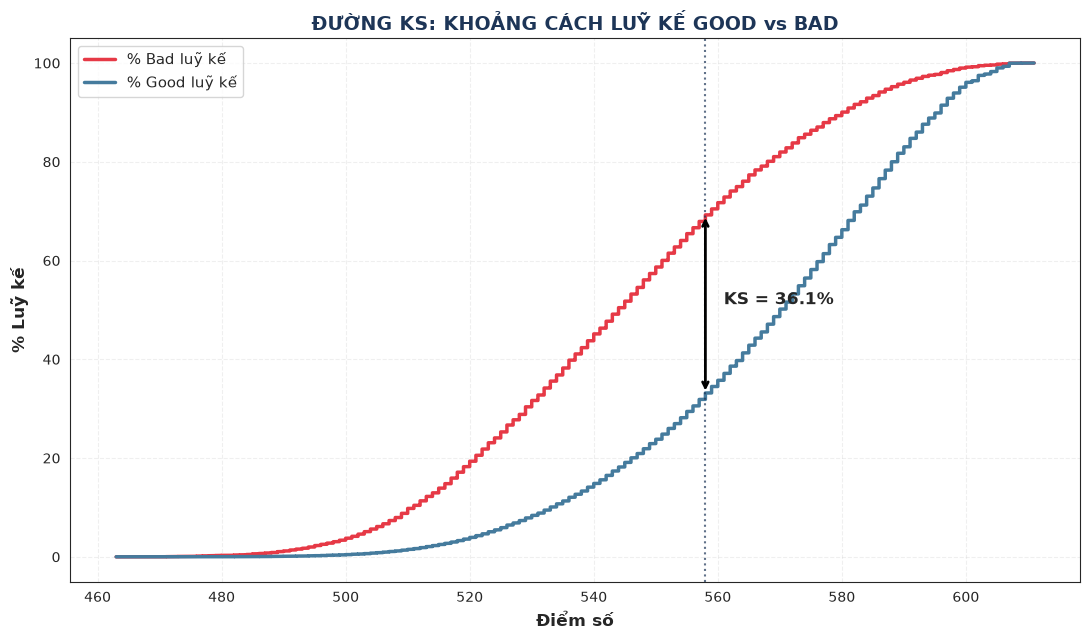

In [11]:
# ===== PHẦN G: Tính KS (Kolmogorov-Smirnov) trên tập Train =====
def calc_ks(scores, target):
    '''Trả về (KS%, điểm tại đó KS đạt max, bảng luỹ kế chi tiết).'''
    df_ks = pd.DataFrame({'score': scores, 'target': target}).sort_values('score').reset_index(drop=True)
    n_bad = df_ks['target'].sum()
    n_good = len(df_ks) - n_bad
    df_ks['Cum_Bad_%']  = df_ks['target'].cumsum() / n_bad * 100
    df_ks['Cum_Good_%'] = (1 - df_ks['target']).cumsum() / n_good * 100
    df_ks['KS_gap'] = np.abs(df_ks['Cum_Bad_%'] - df_ks['Cum_Good_%'])
    idx_max = df_ks['KS_gap'].idxmax()
    return df_ks['KS_gap'].max(), df_ks.loc[idx_max, 'score'], df_ks

ks_stat, ks_score, df_ks_curve = calc_ks(df_model['TOTAL_SCORE'], df_model[TARGET])

danh_gia_ks = ("Yếu" if ks_stat < 20 else "Chấp nhận được" if ks_stat < 40
               else "Tốt, chuẩn ngành" if ks_stat <= 60 else "Nghi ngờ overfit/leakage")
print(f"KS = {ks_stat:.2f}%  (đạt tại điểm ~{ks_score:.0f})  ->  {danh_gia_ks}")

# --- Hình minh hoạ: hai đường luỹ kế Good/Bad + khoảng cách KS ---
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.plot(df_ks_curve['score'], df_ks_curve['Cum_Bad_%'], color='#E63946', linewidth=2.5, label='% Bad luỹ kế')
ax.plot(df_ks_curve['score'], df_ks_curve['Cum_Good_%'], color='#457B9D', linewidth=2.5, label='% Good luỹ kế')
ax.axvline(ks_score, color='#1D3557', linestyle=':', alpha=0.7)
idx_max = df_ks_curve['KS_gap'].idxmax()
y1, y2 = df_ks_curve.loc[idx_max, ['Cum_Bad_%', 'Cum_Good_%']]
ax.annotate('', xy=(ks_score, max(y1, y2)), xytext=(ks_score, min(y1, y2)),
            arrowprops=dict(arrowstyle='<->', color='black', lw=2))
ax.text(ks_score + (df_ks_curve['score'].max() - df_ks_curve['score'].min()) * 0.02,
        (y1 + y2) / 2, f"KS = {ks_stat:.1f}%", fontweight='bold', fontsize=12)
ax.set_xlabel('Điểm số', fontsize=12, fontweight='bold')
ax.set_ylabel('% Luỹ kế', fontsize=12, fontweight='bold')
ax.set_title('ĐƯỜNG KS: KHOẢNG CÁCH LUỸ KẾ GOOD vs BAD', fontsize=14, fontweight='bold', color='#1D3557')
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.3)
fig.tight_layout()
plt.savefig(OUTPUT_DIR / "7a.KS_Chart.png", dpi=300, bbox_inches='tight')
plt.show()

## Phần H — HHI (Herfindahl–Hirschman Index): danh mục có dồn cục vào 1 hạng không?

HHI là chỉ số kinh tế học đo **độ tập trung**: $HHI = \sum_{i=1}^{n} \left(\dfrac{Customers_i}{Total}\right)^2$

Áp cho scorecard: nếu 10 hạng nhưng 80% khách dồn hết vào 2-3 hạng giữa, Master Scale gần như vô dụng cho việc phân biệt rủi ro/định giá — vì "hạng" không còn tách bạch được khách hàng. HHI cao = quá dồn cục; HHI thấp = dàn trải đều.

**Lưu ý khi đọc ngưỡng:** thang HHI chuẩn ngành tài chính (< 0.15 phân tán, > 0.25 tập trung cao) được xây cho thị trường có *rất nhiều* đơn vị (ví dụ hàng chục ngân hàng). Với đúng 10 hạng, mức "chia đều tuyệt đối" đã có HHI = 1/10 = 0.10 — không phải 0. Vì vậy notebook này còn tính thêm **HHI chuẩn hoá**:

$$HHI_{norm} = \frac{HHI - \frac{1}{n}}{1 - \frac{1}{n}} \quad \in [0, 1]$$

0 = phân bổ đều tuyệt đối giữa 10 hạng, 1 = 100% khách dồn vào đúng 1 hạng. Đây là con số nên báo cáo, vì nó không phụ thuộc số hạng đang dùng.

HHI thô        = 0.1344   (mức chia đều tuyệt đối với 10 hạng = 0.1000)
HHI chuẩn hoá  = 0.0382  (0 = đều tuyệt đối, 1 = dồn 1 hạng)  ->  Phân tán tốt


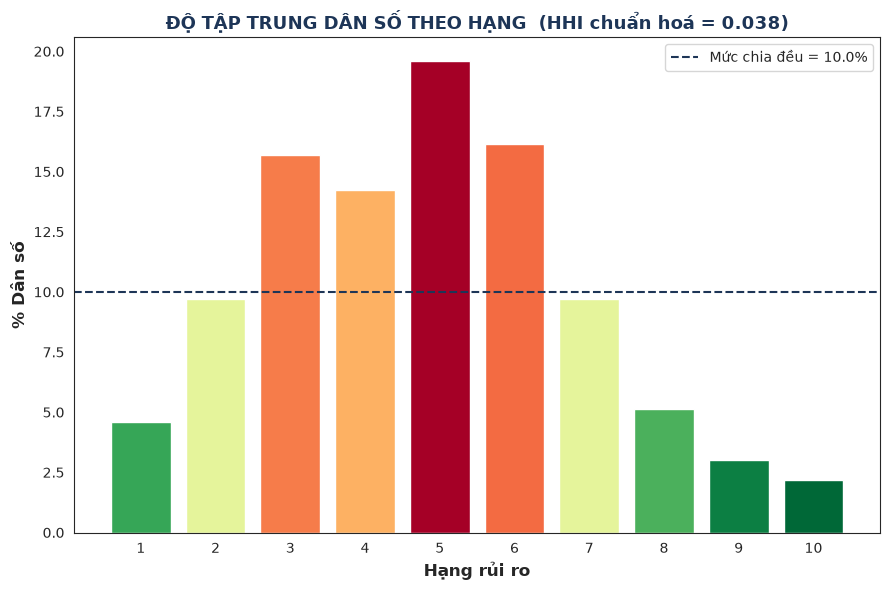

In [12]:
# ===== PHẦN H: Tính HHI trên phân bổ dân số 10 hạng (Train) =====
shares = summary['Total_Customers'] / summary['Total_Customers'].sum()
hhi = (shares ** 2).sum()
n_grade = len(summary)
hhi_norm = (hhi - 1 / n_grade) / (1 - 1 / n_grade)

danh_gia_hhi = "Phân tán tốt" if hhi_norm < 0.10 else "Chấp nhận được" if hhi_norm < 0.25 else "Dồn cục — cân nhắc thiết kế lại target_dist"
print(f"HHI thô        = {hhi:.4f}   (mức chia đều tuyệt đối với {n_grade} hạng = {1/n_grade:.4f})")
print(f"HHI chuẩn hoá  = {hhi_norm:.4f}  (0 = đều tuyệt đối, 1 = dồn 1 hạng)  ->  {danh_gia_hhi}")

fig, ax = plt.subplots(figsize=(9, 6))
colors_hhi = plt.cm.RdYlGn_r((shares.values - shares.min()) / (shares.max() - shares.min() + 1e-9))
ax.bar(summary['RISK_GRADE'], shares.values * 100, color=colors_hhi, edgecolor='white')
ax.axhline(100 / n_grade, color='#1D3557', linestyle='--', label=f'Mức chia đều = {100/n_grade:.1f}%')
ax.set_xlabel('Hạng rủi ro', fontsize=12, fontweight='bold')
ax.set_ylabel('% Dân số', fontsize=12, fontweight='bold')
ax.set_title(f'ĐỘ TẬP TRUNG DÂN SỐ THEO HẠNG  (HHI chuẩn hoá = {hhi_norm:.3f})',
             fontsize=13, fontweight='bold', color='#1D3557')
ax.set_xticks(summary['RISK_GRADE'])
ax.legend()
fig.tight_layout()
plt.savefig(OUTPUT_DIR / "7b.HHI_Chart.png", dpi=300, bbox_inches='tight')
plt.show()

## Phần K — Tra cứu điểm khách hàng theo `SK_ID_CURR`

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============ CHỈ THAY CHỖ NÀY ============
sk_id = 100010
# =========================================

print(f"\n🔍 Đang tìm SK_ID = {sk_id} trong tất cả tập...\n")

# Load tất cả file
files_map = {
    'TRAIN': '../outputs/0.data_train_split.csv',
    'VALIDATION': '../outputs/0.data_valid_split.csv',
    'TEST': '../outputs/data_test.csv'  # Nếu có, không thì bỏ
}

# Tìm file chứa SK_ID
df = None
nguon = None

for name, fpath in files_map.items():
    try:
        df_temp = pd.read_csv(fpath)
        if sk_id in df_temp['SK_ID_CURR'].values:
            df = df_temp
            nguon = name
            print(f"✅ Tìm thấy SK_ID = {sk_id} trong tập: {nguon}")
            break
    except FileNotFoundError:
        pass

# Nếu không tìm thấy
if df is None:
    print(f"❌ SK_ID = {sk_id} KHÔNG tìm thấy trong bất kỳ tập nào!")
    print("\n📋 Kiểm tra các SK_ID mẫu trong từng tập:")
    
    for name, fpath in files_map.items():
        try:
            df_temp = pd.read_csv(fpath)
            print(f"\n{name}:")
            print(f"  SK_ID min-max: {df_temp['SK_ID_CURR'].min()}-{df_temp['SK_ID_CURR'].max()}")
            print(f"  10 SK_ID đầu: {df_temp['SK_ID_CURR'].head(10).tolist()}")
        except FileNotFoundError:
            print(f"\n{name}: File không tồn tại")
    exit()

# Tìm khách
khach = df[df['SK_ID_CURR'] == sk_id].iloc[0]
print(f"\n")

# Load luật + scorecard
df_rules = pd.read_excel("../outputs/1.binning_survey_report.xlsx")
df_scorecard = pd.read_excel("../outputs/4.FINAL_SCORECARD_REPORT.xlsx")
df_master = pd.read_excel("../outputs/5.MASTER_SCALE_HIGH_VOLUME.xlsx")

# 8 biến chốt
vars_8 = ['EXT_SOURCE_AVG', 'LTV_RATIO', 'late_ratio_12m', 'cc_util_12m',
          'prev_app_credit_ratio', 'bureau_debt_ratio', 'refusal_rate', 'total_inst_prescribed']

# Chấm
print(f"{'STT':<4} {'BIẾN':<30} {'GIÁ TRỊ':<15} {'WoE':<10} {'ĐIỂM':<6}")
print(f"{'-'*80}")

tong = 0
for i, var in enumerate(vars_8, 1):
    val = khach[var]
    
    # Tìm WoE từ bảng luật
    if pd.isna(val):
        rule = df_rules[(df_rules['variable'] == var) & (df_rules['cut_point'] == 'Missing')]
    else:
        if df[var].dtype == 'object':
            rule = df_rules[(df_rules['variable'] == var) & (df_rules['cut_point'] == val)]
        else:
            rule = df_rules[(df_rules['variable'] == var) & 
                           (df_rules['min'] <= val) & (val < df_rules['max'])]
    
    if len(rule) == 0:
        woe = 0.0
    else:
        woe = rule.iloc[0]['woe']
    
    # Tìm điểm từ scorecard
    score_row = df_scorecard[(df_scorecard['variable'] == var) & 
                             (np.isclose(df_scorecard['woe'], woe))]
    
    if len(score_row) > 0:
        diem = int(score_row.iloc[0]['Score_Points'])
    else:
        diem = 0
    
    tong += diem
    
    val_str = f"{val:.2f}" if isinstance(val, (int, float)) and not pd.isna(val) else str(val)[:13]
    print(f"{i:<4} {var:<30} {val_str:<15} {woe:>9.4f} {diem:>6}")

print(f"{'-'*80}")
print(f"TỔNG ĐIỂM: {tong}")

# Tra hạng từ master scale
try:
    hang_info = df_master[df_master['RISK_GRADE'] <= tong]
    if len(hang_info) > 0:
        hang_info = hang_info.iloc[-1]
        hang = int(hang_info['RISK_GRADE'])
        bad_rate = hang_info['Bad_Rate (%)']
        print(f"HẠNG: G{hang}")
        print(f"Bad Rate benchmark: {bad_rate:.2f}%")
    else:
        print(f"⚠️ Không tìm được hạng")
except Exception as e:
    print(f"⚠️ Lỗi khi tra hạng: {e}")

# Nếu có cột TARGET thì hiển thị thực tế
if 'TARGET' in khach.index:
    target = khach['TARGET']
    print(f"\nThực tế: {'✅ TỐT (trả đủ)' if target == 0 else '❌ XẤU (vỡ nợ)'}")

print(f"\n{'='*80}")
print(f"✅ Hoàn tất - Nguồn: {nguon}")
print(f"{'='*80}")
